# Molde loading

In [107]:
import sys
import os
from pathlib import Path
from dotenv import load_dotenv, find_dotenv

print("Python executable:", sys.executable)
print("Working directory:", Path.cwd())
print("Found .env:", find_dotenv())
print("Tracing:", os.getenv("LANGSMITH_TRACING"))
print("Project:", os.getenv("LANGSMITH_PROJECT"))
print("API key loaded:", bool(os.getenv("LANGSMITH_API_KEY")))

Python executable: m:\hackthon\Hackathon\.venv\Scripts\python.exe
Working directory: m:\hackthon\Hackathon
Found .env: m:\hackthon\Hackathon\.env
Tracing: true
Project: realhackathon
API key loaded: True


In [1]:
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
import os

print("Tracing:", os.getenv("LANGSMITH_TRACING"))
print("API key loaded:", bool(os.getenv("LANGSMITH_API_KEY")))
print("LANGSMITH_AGENT_ID:", os.getenv("LANGSMITH_AGENT_ID"))

Tracing: true
API key loaded: True
LANGSMITH_AGENT_ID: realhackathon


In [4]:
from langchain_core.runnables import RunnableLambda

chain = RunnableLambda(lambda x: {"result": x["value"] * 2})

result = chain.invoke({"value": 21})

print(result)

{'result': 42}


In [99]:
from langsmith import Client
from langchain_core.runnables import RunnableLambda
import time

client = Client()

chain = RunnableLambda(lambda x: {"result": x["value"] * 2})

result = chain.invoke(
    {"value": 21},
    config={
        "run_name": "notebook-tracing-test",
        "tags": ["debug"],
    },
)

print("Result:", result)

# Give the tracing background worker time to deliver the run.
time.sleep(5)

print("Project:", os.getenv("LANGSMITH_PROJECT"))
print("Client created:", client is not None)

C:\Users\User\AppData\Local\Temp\ipykernel_23084\2023871090.py:5: LangSmithWarning: The address from LANGSMITH_AGENT_ID and LANGSMITH_AGENT_ENVIRONMENT ({'kind': 'AGENT', 'id': 'hackathon', 'environment': 'LOCAL'}) and a configured project ('realhackathon') are both set in the environment, so calls that name no destination in code are not traced. Unset one of them.
  client = Client()


Result: {'result': 42}
Project: realhackathon
Client created: True


In [2]:
from langchain_ollama import ChatOllama
model_name = "qwen3:4b"
llm = ChatOllama(model=model_name, temperature=0.1)
llm_routing = ChatOllama(model=model_name, temperature=0, think=False, keep_alive=0)

# Utlis

In [3]:
from langchain_core.messages import HumanMessage, trim_messages

def last_humain_message(messages: list) -> list:
    for mes in messages[::-1]:
        if isinstance(mes, HumanMessage):
            return [mes]

def do_trim_messages(messages):
    
    return trim_messages(
        messages,
        max_tokens=1000,
        strategy="last",
        token_counter=ChatOllama(model=model_name),
        start_on="human",
        include_system=True,
        allow_partial=False,
    )

# Full Agent

## Routing Agents

### Routting Agent Schema

In [4]:
from langgraph.graph import StateGraph, END, START, add_messages
from pydantic import BaseModel, Field
from typing import Annotated, TypedDict, Literal
from langchain_core.messages import BaseMessage


class AgentState(TypedDict):
    # user_id: str = None
    messages: Annotated[list[BaseMessage], add_messages]
    active_agent: str
    target_route: str
    lang: Literal["en", "fr","jp"]
    # retries: int = 3

class SupervisorDecision(BaseModel):
    target_route: Literal["events", "business", "membership", "HR&Training", "none"] = Field(
        description=("The sub-graph to route to. Use 'none' if you need to ask the user a clarifying question."
                     "events: The CCIFJ hosts over 100 regular events (Galas, Networking) AND massive sector-specific 'Business Summits' (Mobility, Energy, Healthcare, Aeronautics). They also rent out a physical room called L'Espace@CCIFJ. select it when the user need to Handle event discovery, ticket booking, and room rentals."
                     "membership: They have over 650 member companies and 1,500 decision-makers. They offer different tiers (Benefactor, Active, Start-up, Non-resident) and an exclusive app (CCIFI Connect) select it when user need to Sell memberships, explain benefits, and act as a matchmaking concierge to search the member directory."
                     "business: This is their B2B consulting arm. They help French companies enter Japan with services like 'Implantation' (Setup), Business Centers (domiciliation), Market Studies, and specifically, VAT Recovery (Récupération de TVA) select it when user need to Answer complex legal/market questions and capture high-value B2B consulting leads."
                     "HR&Training: select it when (Match candidates to jobs, and register corporate staff for training workshops).")
    )
    clarification_response: str = Field(
        description="The text response to send to the user. E.g., 'Are you looking for tickets or visas?' or 'Transferring you to Events...'"
    )
    lang: Literal["en", "fr","jp"] = Field(description="the language user use to chat with the agent")

### Routting Agent Node

In [5]:
from langchain_core.messages import AIMessage

async def async_supervisor_node(state: AgentState):

    # Bind the Pydantic schema to the LLM
    structured_llm = llm_routing.with_structured_output(SupervisorDecision)
    
    # Define the system prompt
    system_prompt = (
        "You are the CCIFJ digital receptionist. Read the conversation. "
        "If the user's intent is clear, route them to 'events', 'business', 'membership' or 'HR&Training'. "
        "If it is ambiguous, output route 'none' and write a clarification_response asking what they need."
    )
    
    # Call the LLM asynchronously
    response = await structured_llm.ainvoke(
        [{"role": "system", "content": system_prompt}] + last_humain_message(state["messages"])
    )
    
    # Update the graph state
    if response.target_route == "none":
        return {
            "target_route": response.target_route,
            "messages": [AIMessage(content=response.clarification_response)],
            "lang": response.lang
        }
    return {
        "target_route": response.target_route,
        "lang": response.lang
    }

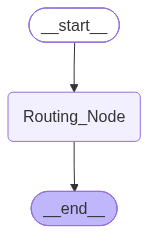

In [6]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

graph = StateGraph(AgentState)


graph.add_node("Routing_Node", async_supervisor_node)

graph.add_edge(START, "Routing_Node")
graph.add_edge("Routing_Node", END)

cgarph = graph.compile(checkpointer=memory)

from IPython.display import Image

Image(cgarph.get_graph().draw_mermaid_png())

In [6]:
SESSION_ID = "notebook_test_123"

config = {"configurable": {"thread_id": SESSION_ID}}

res = await cgarph.ainvoke({"messages":["i want to book a takit for tokyo event , book it for me"], "active_agent": None, "target_route": None}, config=config)

CancelledError: 

In [12]:
res

{'messages': [HumanMessage(content='hello how are you', additional_kwargs={}, response_metadata={}, id='cad8d301-d5b6-4a19-8c74-1ef6b252d522'),
  HumanMessage(content='hello how are you', additional_kwargs={}, response_metadata={}, id='6aec72cb-26f2-4a15-a884-0f54db4d1b20'),
  HumanMessage(content='hello how are you', additional_kwargs={}, response_metadata={}, id='b5a98a0f-071c-4313-b75f-48181f0f50dd'),
  AIMessage(content='Hello! How can I assist you today?', additional_kwargs={}, response_metadata={}, id='705a1798-e785-43a9-8dde-92f22694c325', tool_calls=[], invalid_tool_calls=[])],
 'active_agent': None,
 'target_route': 'none'}

In [14]:
res

{'messages': [HumanMessage(content='hello how are you', additional_kwargs={}, response_metadata={}, id='cad8d301-d5b6-4a19-8c74-1ef6b252d522'),
  HumanMessage(content='hello how are you', additional_kwargs={}, response_metadata={}, id='6aec72cb-26f2-4a15-a884-0f54db4d1b20'),
  HumanMessage(content='hello how are you', additional_kwargs={}, response_metadata={}, id='b5a98a0f-071c-4313-b75f-48181f0f50dd'),
  AIMessage(content='Hello! How can I assist you today?', additional_kwargs={}, response_metadata={}, id='705a1798-e785-43a9-8dde-92f22694c325', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='i want to book a takit for tokyo event , book it for me', additional_kwargs={}, response_metadata={}, id='76009cba-f76b-48be-afd0-6f35ea52e16d'),
  AIMessage(content='', additional_kwargs={}, response_metadata={}, id='8004626e-3d95-411d-ada8-2d3e34c678c8', tool_calls=[], invalid_tool_calls=[])],
 'active_agent': None,
 'target_route': 'events'}

## Event Agent

### Event Agent Schema

In [7]:
class EventsState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    task_completed: bool
    lang: Literal["en", "fr","jp"]

### Event tools

In [8]:
from langchain.tools import tool

@tool
def specific_search_events_db(search_on: str, search_use: str) -> str:
    """Use this tool to search the events database for relevant events based on the user's query (based on event dates, place or names)
    and return the specific event details.
    search_on: can be [event_name, event_date, event_location]
    search_use: can be like [tokyo gala 2026, 2026-10-15, tokyo]
    """

    if search_on == "event_name":
        if search_use.lower() == "tokyo gala 2026":
            return "Found Tokyo Gala 2026 event. Tickets are available. place: Tokyo, date: 2026-10-15, event_id: 12345."
        return "No events found for that name."
    elif search_on == "event_date":
        if search_use == "2026-10-15":
            return "Found Tokyo Gala 2026 event on 2026-10-15. Tickets are available. place: Tokyo, event_id: 54321."
        return "No events found for that date."
    elif search_on == "event_location":
        if search_use.lower() == "tokyo":
            return "Found Tokyo Gala 2026 event in Tokyo. Tickets are available. date: 2026-10-15, event_id: 98765."
        return "No events found for that location."
    else:
        return "Invalid search criteria. Please use 'event_name', 'event_date', or 'event_location'."

@tool
def search_events_db(search_on: str) -> str:
    """Use this tool to search the events database for relevant events based on the user's query (based on event dates, place or names).
        and return a list of events that match the search criteria
        search_on: event_name -> return all avilable events
        search_on: event_date -> return all dates that has an event at this days."""

    if search_on == "event_name":
        return "Found events: Tokyo Gala 2026, Kyoto Festival 2026, Osaka Tech Expo 2026."
    elif search_on == "event_date":
        return "Found events on that date: 2026-10-15, 2026-12-15, 2026-10-30"
    elif search_on == "event_location":
        return "Found events in that location: Tokyo Gala, Tokyo Anime Fair."
    else:
        return "Invalid search criteria. Please use 'event_name', 'event_date', or 'event_location'."

@tool
def book_ticket(event_id: str) -> str:
    """Use this func to book ticket based on event id (use specific_search_events_db to find the event id with other details)"""

    return "ticket booked successfully"

@tool
def return_to_main_menu():
    """Call this tool when the event task is finished or user wants other services."""
    return "Returned."


### Create Event agent using langchain agent

In [9]:
from langchain.agents import create_agent


EVENT_AGENT_PROMPT = """
You are the CCIFJ Events Concierge. Help users find events and guide them
through ticket reservations in a friendly, professional way.

## What you can do
- Find events using `search_events_db`.
- Look up an event using `specific_search_events_db`.
- Use `book_ticket` only after the user has clearly chosen an event and
  explicitly asked to book.
- Use `return_to_main_menu` when the user asks for another service or is
  finished with event assistance.

## How to handle requests
1. Identify what the user wants: event listings, details about a particular
   event, or help booking.
2. If they haven't provided enough information to find the right event,
   ask a brief clarifying question. Don't guess which event they mean.
3. Use the event search tools for event facts. Base dates, locations,
   availability, and event IDs on tool results; don't invent or infer them.
4. Before booking, make sure the user has selected a specific event and
   explicitly confirmed that they want to book. Ask for the attendee name
   and ticket count first if needed, but don't imply those details were
   recorded unless a tool supports it.
5. If a search returns no match, say so and offer a useful next step, such
   as searching by name, date, or location.
6. If the user changes topic to membership, business services, HR, or
   training, briefly acknowledge the request and call
   `return_to_main_menu`.

## Accuracy and trust
- Never claim a booking is real or confirmed unless the booking system
  actually confirms it.
- If a tool gives only a simulated or demo result, clearly describe it as
  a demo—not a real reservation.
- Don't make up ticket prices, event details, policies, or availability.
  Say when the available tools don't provide the requested information.
- Don't ask users to share payment-card details or other sensitive
  information in chat.

## Communication
- Reply in the language the user is using: English, French, or Japanese.
- Be concise, warm, and specific. Ask one focused question at a time.
- After giving event information, offer a relevant next step without
  pressuring the user.

##
- if the user question does not related to the subagent task do not write any response and just call the return_to_main_menu
"""

tools = [specific_search_events_db, search_events_db, book_ticket, return_to_main_menu]
envet_agent = create_agent(
    llm,
    tools=tools,
    system_prompt=EVENT_AGENT_PROMPT
)

### Build Event Subgraph

In [10]:
async def evnet_agent_warkflow(state: EventsState):
    agent_messages = do_trim_messages(state["messages"])

    result = await envet_agent.ainvoke({
        "messages": agent_messages
    })

    new_agent_messages = result["messages"][len(agent_messages):]

    is_done = any(
    call["name"] == "return_to_main_menu"
    for msg in new_agent_messages
    if isinstance(msg, AIMessage)
    for call in getattr(msg, "tool_calls", [])
    )

    return {
        "messages": new_agent_messages,
        "task_completed": is_done
    }

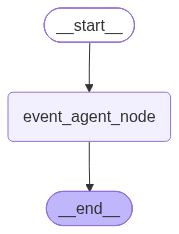

In [11]:
event_subgraph = StateGraph(EventsState)

## add nodes
event_subgraph.add_node("event_agent_node", evnet_agent_warkflow)

## add edges
event_subgraph.add_edge(START, "event_agent_node")
event_subgraph.add_edge("event_agent_node", END)

cevent_subgraph = event_subgraph.compile()

from IPython.display import Image

Image(cevent_subgraph.get_graph().draw_mermaid_png())


#### Testing The Event Subgraph

In [12]:
# last test with short tearm memory
SESSION_ID2 = "123456"

config2 = {"configurable": {"thread_id": SESSION_ID2}}

res = await cevent_subgraph.ainvoke({"messages": ["what the evnent avilable these days? i ask in general if you want to use search_events_db use event_date as a cretirea"], "task_completed": False}, config=config2)


m:\hackthon\Hackathon\.venv\Lib\site-packages\langchain_core\language_models\base.py:463: UserWarning: Using fallback GPT-2 tokenizer for token counting. Token counts may be inaccurate for non-GPT-2 models. For accurate counts, use a model-specific method if available.
  return len(self.get_token_ids(text))
m:\hackthon\Hackathon\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CancelledError: 

In [35]:
res

{'messages': [HumanMessage(content='what the evnent avilable these days? i ask in general if you want to use search_events_db use event_date as a cretirea', additional_kwargs={}, response_metadata={}, id='0483196a-d1c3-4bed-9537-03f1937add50'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-21T14:15:59.4720338Z', 'done': True, 'done_reason': 'stop', 'total_duration': 40080308100, 'load_duration': 5747546200, 'prompt_eval_count': 448, 'prompt_eval_duration': 411156000, 'eval_count': 878, 'eval_duration': 33903720999, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a15ed1-065c-7152-b8c7-79ca3bf2a1c3-0', tool_calls=[{'name': 'search_events_db', 'args': {'search_on': 'event_date'}, 'id': '7b1c90ec-8e92-4d4e-b475-44e43aff2568', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 448, 'output_tokens': 878, 'total_tokens': 1326}),
  ToolMessage(content='Found events o

In [36]:
res = await cevent_subgraph.ainvoke({"messages": ["book me the tokyo ticket"], "task_completed": False}, config=config)


In [37]:
res

{'messages': [HumanMessage(content='what the evnent avilable these days? i ask in general if you want to use search_events_db use event_date as a cretirea', additional_kwargs={}, response_metadata={}, id='0483196a-d1c3-4bed-9537-03f1937add50'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-21T14:15:59.4720338Z', 'done': True, 'done_reason': 'stop', 'total_duration': 40080308100, 'load_duration': 5747546200, 'prompt_eval_count': 448, 'prompt_eval_duration': 411156000, 'eval_count': 878, 'eval_duration': 33903720999, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a15ed1-065c-7152-b8c7-79ca3bf2a1c3-0', tool_calls=[{'name': 'search_events_db', 'args': {'search_on': 'event_date'}, 'id': '7b1c90ec-8e92-4d4e-b475-44e43aff2568', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 448, 'output_tokens': 878, 'total_tokens': 1326}),
  ToolMessage(content='Found events o

In [38]:
res = await cevent_subgraph.ainvoke({"messages": ["my name is mohammad adel khashan and i want two ticket"], "task_completed": False}, config=config)

In [39]:
res

{'messages': [HumanMessage(content='what the evnent avilable these days? i ask in general if you want to use search_events_db use event_date as a cretirea', additional_kwargs={}, response_metadata={}, id='0483196a-d1c3-4bed-9537-03f1937add50'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-21T14:15:59.4720338Z', 'done': True, 'done_reason': 'stop', 'total_duration': 40080308100, 'load_duration': 5747546200, 'prompt_eval_count': 448, 'prompt_eval_duration': 411156000, 'eval_count': 878, 'eval_duration': 33903720999, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a15ed1-065c-7152-b8c7-79ca3bf2a1c3-0', tool_calls=[{'name': 'search_events_db', 'args': {'search_on': 'event_date'}, 'id': '7b1c90ec-8e92-4d4e-b475-44e43aff2568', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 448, 'output_tokens': 878, 'total_tokens': 1326}),
  ToolMessage(content='Found events o

### Build The Event node (used in full graph)

In [12]:
async def events_node(state: AgentState) -> dict:
    # 1. Downcast: Map Parent State -> Child Schema
    child_input: EventsState = {
        "messages": state["messages"],
        "task_completed": False,
        "lang": state["lang"]
    }

    # 2. Invoke the compiled child graph
    child_output = await cevent_subgraph.ainvoke(child_input)

    # 3. Determine if the user is released back to the supervisor
    is_done = child_output.get("task_completed", False)

    # 4. Upcast: Map Child Output -> Parent State
    # Only return the newly generated messages and the updated routing key
    new_messages = child_output["messages"][len(state["messages"]):]

    if is_done:
        return {
            "active_agent": "supervisor",
            "target_route": None
        }
    return {
        "messages": new_messages,
        "active_agent": "events",
    }

## Membership Agent

### Membership schema

In [13]:
class MembershipState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    task_completed: bool
    lang: Literal["en", "fr","jp"]

### Membership tools

In [14]:
from typing import Optional

@tool
def search_member_directory(
    industry: Optional[str] = None,
    region: Optional[str] = None,
):
    """
    Search the CCIFJ member directory (650+ companies).
    Filter by industry (e.g., 'IT', 'Retail') or region (e.g., 'Tokyo', 'Kansai').
    """
    if industry.lower() in ["it", "retail"] and region.lower() in ['tokyo', 'kansai']:
        return """
        the company names:\nAEON CO (イオン株式会社)\nAMAZON JAPAN (アマゾンジャパン合同会社)
        """

@tool
def list_available_industriesAndregion():
    """
    Returns the distinct list of official business sectors available in the CCIFJ directory.
    Call this if you are unsure how an industry is categorized.
    """
    return """"
    industries:\n-IT\n-Retail\n
    regions:\n-tokyo\n-kansai
    """

@tool
def get_membership_tier_info(tier_or_category_name: Optional[str] = None):
    """
    Get pricing, benefits, and category details for CCIFJ membership tiers 
    (the tiers are: ['Benefactor', 'Active', 'Start-up', 'Non-resident', 'Individuale', 'In-region]).
    If no tier is provided, returns an overview of all categories.
    """
    return """
        Active membership is aimed to companies that are looking to increase their visibility,
        develop strong partnerships with the French-Japanese business community while being fully involved in all of the activities of the CCI France Japon.
        Annual membership fee: 295.000 yens
        (From 1st of January to 31st of December)"""


@tool
def get_member_privileges_and_contacts():
    """
    Get exclusive member perks (Help Desk, discounts via CCIFI Connect) 
    and contact details for the CCIFJ membership department.
    """
    return """
    privileges:
    KOSHINO VALLEY -> Members of CCI France Japon are welcome to use Koshino Valley in Fukui free of charge.
    ACCOR HOTELS -> Mercure Hibiya offers exclusive special deals for members, including % off on meeting room rentals, restaurant reservations, and dining plans.
    contacts:
    Tomoyo FUNABASHI (Membership Manager)  03-4500-6644  t.funabashi@ccifj.or.jp
    Marianne BARGES: (Membership Associate Manager & Communication Coordinator) 03-4500-6522 m.barges@ccifj.or.jp
    Erika KATAOKA: (Membership Associate) 03-4500-6607 e.kataoka@ccifj.or.jp
"""

@tool
def get_membership_form(lang: Literal["en", "fr", "jp"]):
    """
    Return the form url so user can fill it to become a member.
    """
    return f"the form url is 'https://survey.ccifi.net/232729?lang={lang}'"

@tool
def return_to_main_menu(summary_message: str):
    """Call this tool when the event task is finished or user wants other services.
    and other service you can not do call this func to go back to the routing node"""
    return "Returned."

### Create Membership Agent Uusing Langchain Agent

In [15]:
Membership_tools = [search_member_directory, list_available_industriesAndregion, get_membership_tier_info,
                    get_member_privileges_and_contacts, get_membership_form, return_to_main_menu]

MEMBERSHIP_AGENT_PROMPT = """You are the official Membership & Community Concierge for the French Chamber of Commerce and Industry in Japan (CCIFJ / CCI France Japon).

### YOUR ROLE & MISSION
1. Assist users with inquiries regarding CCIFJ membership tiers, benefits, pricing, and member privileges (e.g., Help Desk, CCIFI Connect app, discounts).
2. Help users navigate the CCIFJ network by searching the directory of 650+ member companies.
3. Capture sales leads when prospective members express interest in joining or requesting formal onboarding information.

### BEHAVIORAL & COMMUNICATION GUIDELINES
1. Tone: Professional, welcoming, elegant, and helpful—representing a premier European trade chamber in Japan.
2. Language: Respond in the same language used by the user (English, French, or Japanese).
3. Missing Information: If the user provides a vague request (e.g., "I want to join" or "Find me tech companies"), politely ask for clarification (e.g., company name/email, or specific region/sector) BEFORE calling an action tool.
4. Handoff Discipline: Do not try to answer questions outside your scope. If the user asks about upcoming Galas or corporate tax rules, briefly acknowledge their request and invoke `return_to_main_menu`.
"""

membership_agent = create_agent(
    llm,
    tools=Membership_tools,
    system_prompt=MEMBERSHIP_AGENT_PROMPT
)


### Build Membership Subgraph

In [16]:
async def membership_agent_warkflow(state: MembershipState):
    agent_messages = do_trim_messages(state["messages"])
    
    result = await membership_agent.ainvoke({
        "messages": agent_messages
    })

    new_agent_messages = result["messages"][len(agent_messages):]

    is_done = any(
    call["name"] == "return_to_main_menu"
    for msg in new_agent_messages
    if isinstance(msg, AIMessage)
    for call in getattr(msg, "tool_calls", [])
    )

    return {
        "messages": new_agent_messages,
        "task_completed": is_done
    }

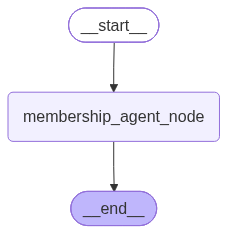

In [17]:
membership_subgraph = StateGraph(MembershipState)

# add nodes
membership_subgraph.add_node("membership_agent_node", membership_agent_warkflow)

## add edgs

membership_subgraph.add_edge(START, "membership_agent_node")
membership_subgraph.add_edge("membership_agent_node", END)

cmembership_subgraph = membership_subgraph.compile()

Image(cmembership_subgraph.get_graph().draw_mermaid_png())

### Test The Membership Subagent

In [47]:
SESSION_ID2 = "123456member"

configmember = {"configurable": {"thread_id": SESSION_ID2}}

res = await cmembership_subgraph.ainvoke({"messages": ["how are you"]}, config=configmember)

In [48]:
res

{'messages': [HumanMessage(content='how are you', additional_kwargs={}, response_metadata={}, id='9faa310b-5886-44f6-a75b-3a153585a70c'),
  AIMessage(content="Hello! I'm the CCIFJ Concierge. How can I assist you today? 😊", additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-22T10:16:05.7599799Z', 'done': True, 'done_reason': 'stop', 'total_duration': 19033395300, 'load_duration': 21133300, 'prompt_eval_count': 758, 'prompt_eval_duration': 416962000, 'eval_count': 451, 'eval_duration': 18417446000, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a1631c-1322-7ca3-94d6-5405b2911de9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 758, 'output_tokens': 451, 'total_tokens': 1209})],
 'task_completed': False}

In [49]:
res = await cmembership_subgraph.ainvoke({"messages": ["what services you provide?"]}, config=configmember)

In [50]:
res

{'messages': [HumanMessage(content='how are you', additional_kwargs={}, response_metadata={}, id='9faa310b-5886-44f6-a75b-3a153585a70c'),
  AIMessage(content="Hello! I'm the CCIFJ Concierge. How can I assist you today? 😊", additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-22T10:16:05.7599799Z', 'done': True, 'done_reason': 'stop', 'total_duration': 19033395300, 'load_duration': 21133300, 'prompt_eval_count': 758, 'prompt_eval_duration': 416962000, 'eval_count': 451, 'eval_duration': 18417446000, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a1631c-1322-7ca3-94d6-5405b2911de9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 758, 'output_tokens': 451, 'total_tokens': 1209}),
  HumanMessage(content='what services you provide?', additional_kwargs={}, response_metadata={}, id='8e2b1eff-8e4c-4b70-8658-cb615fc125f0'),
  AIMessage(content='The CCIFJ offers a range of services including membersh

In [51]:
res["messages"][-1].pretty_print()

================================== Ai Message ==================================

The CCIFJ offers a range of services including membership tiers with tailored benefits, access to a directory of 650+ Japanese companies, Help Desk support, discounts via the CCIFI Connect app, and networking opportunities. How can I assist you today? 😊


In [52]:
res = await cmembership_subgraph.ainvoke({"messages": ["i want to become a member?how to join?"]}, config=configmember)

In [53]:
res

{'messages': [HumanMessage(content='how are you', additional_kwargs={}, response_metadata={}, id='9faa310b-5886-44f6-a75b-3a153585a70c'),
  AIMessage(content="Hello! I'm the CCIFJ Concierge. How can I assist you today? 😊", additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-22T10:16:05.7599799Z', 'done': True, 'done_reason': 'stop', 'total_duration': 19033395300, 'load_duration': 21133300, 'prompt_eval_count': 758, 'prompt_eval_duration': 416962000, 'eval_count': 451, 'eval_duration': 18417446000, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a1631c-1322-7ca3-94d6-5405b2911de9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 758, 'output_tokens': 451, 'total_tokens': 1209}),
  HumanMessage(content='what services you provide?', additional_kwargs={}, response_metadata={}, id='8e2b1eff-8e4c-4b70-8658-cb615fc125f0'),
  AIMessage(content='The CCIFJ offers a range of services including membersh

In [54]:
res = await cmembership_subgraph.ainvoke({"messages": ["sure, the company name is mkhashan and the email is mkhashan@gmail.com"]}, config=configmember)

In [55]:
res

{'messages': [HumanMessage(content='how are you', additional_kwargs={}, response_metadata={}, id='9faa310b-5886-44f6-a75b-3a153585a70c'),
  AIMessage(content="Hello! I'm the CCIFJ Concierge. How can I assist you today? 😊", additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-22T10:16:05.7599799Z', 'done': True, 'done_reason': 'stop', 'total_duration': 19033395300, 'load_duration': 21133300, 'prompt_eval_count': 758, 'prompt_eval_duration': 416962000, 'eval_count': 451, 'eval_duration': 18417446000, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a1631c-1322-7ca3-94d6-5405b2911de9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 758, 'output_tokens': 451, 'total_tokens': 1209}),
  HumanMessage(content='what services you provide?', additional_kwargs={}, response_metadata={}, id='8e2b1eff-8e4c-4b70-8658-cb615fc125f0'),
  AIMessage(content='The CCIFJ offers a range of services including membersh

In [56]:
res = await cmembership_subgraph.ainvoke({"messages": ["no thanks"]}, config=configmember)

In [57]:
res

{'messages': [HumanMessage(content='how are you', additional_kwargs={}, response_metadata={}, id='9faa310b-5886-44f6-a75b-3a153585a70c'),
  AIMessage(content="Hello! I'm the CCIFJ Concierge. How can I assist you today? 😊", additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-22T10:16:05.7599799Z', 'done': True, 'done_reason': 'stop', 'total_duration': 19033395300, 'load_duration': 21133300, 'prompt_eval_count': 758, 'prompt_eval_duration': 416962000, 'eval_count': 451, 'eval_duration': 18417446000, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a1631c-1322-7ca3-94d6-5405b2911de9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 758, 'output_tokens': 451, 'total_tokens': 1209}),
  HumanMessage(content='what services you provide?', additional_kwargs={}, response_metadata={}, id='8e2b1eff-8e4c-4b70-8658-cb615fc125f0'),
  AIMessage(content='The CCIFJ offers a range of services including membersh

In [64]:
SESSION_ID2 = "123456member3"

configmember = {"configurable": {"thread_id": SESSION_ID2}}

async for chunk in cmembership_subgraph.astream(
    {
        "messages": [
            "tell me about you service what category you have and what benift you provides? give me as much info as you can"
        ]
    },
    config=configmember,
    stream_mode="debug"
):
    print(chunk)

{'step': -1, 'timestamp': '2026-10-22T10:33:57.647380+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': '123456member3', 'checkpoint_id': '1f1ce041-66aa-60ca-bfff-3dbed7b00c40'}}, 'parent_config': None, 'values': {'messages': []}, 'metadata': {'source': 'input', 'step': -1, 'parents': {}}, 'next': ['__start__'], 'tasks': [{'id': '9394cf18-f298-e5e4-e5af-bbb7d5b2198c', 'name': '__start__', 'interrupts': (), 'state': None}]}}
{'step': 0, 'timestamp': '2026-10-22T10:33:57.648377+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': '123456member3', 'checkpoint_id': '1f1ce041-66ac-67c0-8000-4343f2e13a3b'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': '123456member3', 'checkpoint_id': '1f1ce041-66aa-60ca-bfff-3dbed7b00c40'}}, 'values': {'messages': [HumanMessage(content='tell me about you service what category you have and what benift you provides? give me as much

### Build the membership nodes

In [18]:
async def membership_node(state: AgentState) -> dict:
    # 1. Downcast: Map Parent State -> Child Schema
    child_input: MembershipState = {
        "messages": state["messages"],
        "task_completed": False,
        "lang": state["lang"]
    }

    # 2. Invoke the compiled child graph
    child_output = await cmembership_subgraph.ainvoke(child_input)

    # 3. Determine if the user is released back to the supervisor
    is_done = child_output.get("task_completed", False)

    # 4. Upcast: Map Child Output -> Parent State
    # Only return the newly generated messages and the updated routing key
    new_messages = child_output["messages"][len(state["messages"]):]

    if is_done:
        return {
            "active_agent": "supervisor",
            "target_route": None
        }
    return {
        "messages": new_messages,
        "active_agent": "membership",
        "target_route": None
    }

## Business Agent

### Business Schema

In [19]:
class BusinessState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    task_completed: bool
    lang: Literal["en", "fr","jp"]

### Business Tools

In [20]:
@tool
def use_RAG(query):
    """
    Use this tool when you want to search out vector db to search about most relevant context to answer based on.
    you can use it more than one time with different query to try to got the correct query.
    """
    return ""



### Create Business Agent Using Langchain Agent

In [23]:
from concierge.agents.tools import *
Business_tools = [search_vectordb]

BUSINESS_AGENT_PROMPT = """
You are the CCIFJ Business Services Concierge. Help companies understand
how CCIFJ may support their business activities in Japan.

## Topics you can help with
These may include market-entry support, business setup (implantation),
business-center or domiciliation services, market studies, and VAT recovery.
Treat these as areas to investigate—not as promises that a particular
service or outcome is available.

## Use of information
- Use `use_RAG` to look for relevant, source-grounded information before
  answering factual questions about CCIFJ services, requirements, processes,
  fees, timelines, or Japan-market topics.
- Ask focused queries. If the result is incomplete, you may search again
  with a more specific query.
- Base factual claims on the retrieved information. Never invent service
  details, prices, eligibility requirements, deadlines, legal rules, or
  guarantees.
- If the tool returns no useful information, say that you couldn't verify
  the answer from the available information and offer to connect the user
  with the appropriate CCIFJ team.
- Distinguish general information from professional advice. Do not present
  legal, tax, immigration, or financial guidance as definitive; recommend
  confirming case-specific questions with a qualified professional.

## Helping prospective clients
- Understand the user's goal and ask only the next necessary question,
  such as their industry, target market, or where they are in their
  Japan-market plans.
- If they want to speak with CCIFJ or request a proposal, summarize their
  needs and ask permission before passing along their details.
- Don't request sensitive personal, financial, or payment information in chat.
- Never claim that a lead was submitted, a consultation was booked, or a
  service was purchased unless a tool actually confirms it.

## Other requests
If the user is asking about events, membership, HR, or training rather than
business services, briefly acknowledge that and call `return_to_main_menu`.

## Communication
- Reply in the language the user is using: English, French, or Japanese.
- Be professional, clear, and concise. Explain unfamiliar business terms
  briefly and end with a relevant next step when helpful.
"""
business_agent = create_agent(
    llm,
    tools=Business_tools,
    system_prompt=BUSINESS_AGENT_PROMPT
)


### Building Business Subgraph

In [24]:
async def business_agent_warkflow(state: BusinessState):
    agent_messages = do_trim_messages(state["messages"])

    result = await business_agent.ainvoke({
        "messages": agent_messages
    })

    new_agent_messages = result["messages"][len(agent_messages):]

    is_done = any(
    call["name"] == "return_to_main_menu"
    for msg in new_agent_messages
    if isinstance(msg, AIMessage)
    for call in getattr(msg, "tool_calls", [])
    )

    return {
        "messages": new_agent_messages,
        "task_completed": is_done
    }

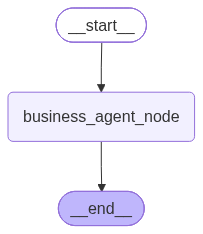

In [25]:
business_subgraph = StateGraph(BusinessState)

# add nodes
business_subgraph.add_node("business_agent_node", business_agent_warkflow)

## add edgs
business_subgraph.add_edge(START, "business_agent_node")
business_subgraph.add_edge("business_agent_node", END)
cbusiness_subgraph = business_subgraph.compile()

Image(cbusiness_subgraph.get_graph().draw_mermaid_png())

## Building The Business Node

In [26]:
async def business_node(state: AgentState) -> dict:
    # 1. Downcast: Map Parent State -> Child Schema
    child_input: BusinessState = {
        "messages": state["messages"],
        "task_completed": False,
        "lang": state["lang"]
    }

    # 2. Invoke the compiled child graph
    child_output = await cbusiness_subgraph.ainvoke(child_input)

    # 3. Determine if the user is released back to the supervisor
    is_done = child_output.get("task_completed", False)

    # 4. Upcast: Map Child Output -> Parent State
    # Only return the newly generated messages and the updated routing key
    new_messages = child_output["messages"][len(state["messages"]):]

    if is_done:
        return {
            "active_agent": "supervisor",
            "target_route": None
        }
    return {
        "messages": new_messages,
        "active_agent": "business",
        "target_route": None
    }

## Sub routing func's

In [27]:
def route_from_start(state: AgentState):
    if state.get("active_agent") == "events":
        return "events_node"
    elif state.get("active_agent") == "membership":
        return "membership_node"
    elif state.get("active_agent") == "business":
            return "business_node"
    return "supervisor_node"

def route_after_supervisor(state: AgentState):
    route = state.get("target_route", "none")
    if route == "events":
        return "events_node"
    elif route == "membership":
        return  "membership_node"
    elif route == "business":
            return  "business_node"
    return "END"

def route_after_subagent(state: AgentState):
    if state.get("active_agent") == "supervisor":
        return "supervisor_node"
    return "END"

## Build The Full Graph

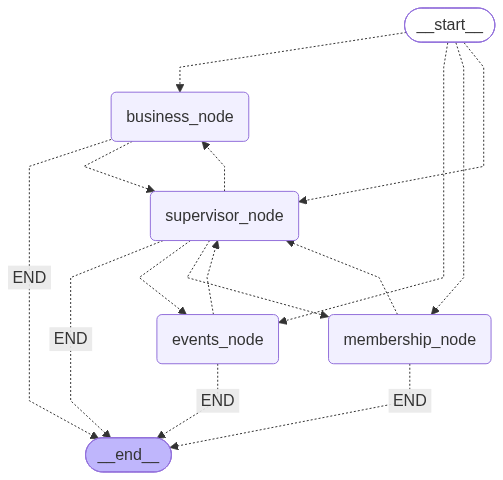

In [28]:
parent_builder = StateGraph(AgentState)

Parent_memory = MemorySaver()
# Add Nodes
parent_builder.add_node("supervisor_node", async_supervisor_node)
parent_builder.add_node("events_node", events_node)
parent_builder.add_node("membership_node", membership_node)
parent_builder.add_node("business_node", business_node)

# Connect edges
parent_builder.add_conditional_edges(START, route_from_start, {"events_node": "events_node", "membership_node": "membership_node", "business_node": "business_node", "supervisor_node": "supervisor_node"})
parent_builder.add_conditional_edges("supervisor_node", route_after_supervisor, {"events_node": "events_node", "membership_node": "membership_node", "business_node": "business_node", "END": END})
parent_builder.add_conditional_edges("events_node", route_after_subagent, {"supervisor_node": "supervisor_node", "END": END})
parent_builder.add_conditional_edges("membership_node", route_after_subagent, {"supervisor_node": "supervisor_node", "END": END})
parent_builder.add_conditional_edges("business_node", route_after_subagent, {"supervisor_node": "supervisor_node", "END": END})

compiled_parent = parent_builder.compile(checkpointer=Parent_memory)

Image(compiled_parent.get_graph().draw_mermaid_png())

## Testing The Full Graph On Event Node

In [40]:
SESSION_ID3 = "12345678"

config3 = {"configurable": {"thread_id": SESSION_ID2}}

res = await compiled_parent.ainvoke({"messages":["i need help can you help me"]}, config=config3)

In [41]:
res

{'messages': [HumanMessage(content='i need help can you help me', additional_kwargs={}, response_metadata={}, id='89927977-b0ec-4994-850d-a91aca828c9e'),
  AIMessage(content='Sure! What specific help do you need? (e.g., events, business, or membership)', additional_kwargs={}, response_metadata={}, id='8fbc291c-299a-4976-be77-90b16a551723', tool_calls=[], invalid_tool_calls=[])],
 'target_route': 'none'}

In [42]:
res = await compiled_parent.ainvoke({"messages":["i want to attend an event at tokyo is there any one will take place soon and has an avilable ticket ?"]}, config=config3)

In [43]:
res

{'messages': [HumanMessage(content='i need help can you help me', additional_kwargs={}, response_metadata={}, id='89927977-b0ec-4994-850d-a91aca828c9e'),
  AIMessage(content='Sure! What specific help do you need? (e.g., events, business, or membership)', additional_kwargs={}, response_metadata={}, id='8fbc291c-299a-4976-be77-90b16a551723', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='i want to attend an event at tokyo is there any one will take place soon and has an avilable ticket ?', additional_kwargs={}, response_metadata={}, id='d57423de-30b8-4edb-a07e-d784c5db828b'),
  AIMessage(content='', additional_kwargs={}, response_metadata={}, id='751e445e-37de-4b0b-8fd3-f2130c5189e7', tool_calls=[], invalid_tool_calls=[]),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-21T14:37:30.8907915Z', 'done': True, 'done_reason': 'stop', 'total_duration': 114028696700, 'load_duration': 16465100, 'prompt_eval_count': 477,

In [44]:
res = await compiled_parent.ainvoke({"messages":["pls book three tickets with name mohammad adel khashan"]}, config=config3)

In [45]:
res

{'messages': [HumanMessage(content='i need help can you help me', additional_kwargs={}, response_metadata={}, id='89927977-b0ec-4994-850d-a91aca828c9e'),
  AIMessage(content='Sure! What specific help do you need? (e.g., events, business, or membership)', additional_kwargs={}, response_metadata={}, id='8fbc291c-299a-4976-be77-90b16a551723', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='i want to attend an event at tokyo is there any one will take place soon and has an avilable ticket ?', additional_kwargs={}, response_metadata={}, id='d57423de-30b8-4edb-a07e-d784c5db828b'),
  AIMessage(content='', additional_kwargs={}, response_metadata={}, id='751e445e-37de-4b0b-8fd3-f2130c5189e7', tool_calls=[], invalid_tool_calls=[]),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-21T14:37:30.8907915Z', 'done': True, 'done_reason': 'stop', 'total_duration': 114028696700, 'load_duration': 16465100, 'prompt_eval_count': 477,

In [46]:
res = await compiled_parent.ainvoke({"messages":["ok thank you"]}, config=config3)

In [47]:
res

{'messages': [HumanMessage(content='i need help can you help me', additional_kwargs={}, response_metadata={}, id='89927977-b0ec-4994-850d-a91aca828c9e'),
  AIMessage(content='Sure! What specific help do you need? (e.g., events, business, or membership)', additional_kwargs={}, response_metadata={}, id='8fbc291c-299a-4976-be77-90b16a551723', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='i want to attend an event at tokyo is there any one will take place soon and has an avilable ticket ?', additional_kwargs={}, response_metadata={}, id='d57423de-30b8-4edb-a07e-d784c5db828b'),
  AIMessage(content='', additional_kwargs={}, response_metadata={}, id='751e445e-37de-4b0b-8fd3-f2130c5189e7', tool_calls=[], invalid_tool_calls=[]),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-21T14:37:30.8907915Z', 'done': True, 'done_reason': 'stop', 'total_duration': 114028696700, 'load_duration': 16465100, 'prompt_eval_count': 477,

## Testing With Event and Membership Node

In [24]:
SESSION_ID = "ev_mem_1"
config_ev_mem = {"configurable": {"thread_id": SESSION_ID}}

res1 = await compiled_parent.ainvoke({"messages": "how are you can you helo me"}, config=config_ev_mem)
res1

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[])],
 'target_route': 'none',
 'lang': 'en'}

In [25]:
res2 = await compiled_parent.ainvoke({"messages": "what kind of service you can help me with tell me more about your interprise?"}, config=config_ev_mem)
res2

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='what kind of service you can help me with tell me more about your interprise?', additional_kwargs={}, response_metadata={}, id='affef34a-03c7-4566-9127-5c96c4e0dcba'),
  AIMessage(content="I see you're asking about what services I can help with and more about our enterprise. Could you clarify what specific area you'd like to explore? For example, are you interested in events, business resources, membership benefits, or HR & Training programs?", additional_kwa

In [26]:
res3 = await compiled_parent.ainvoke({"messages": "tell me more about the membership i mean what kind of membership there exist what the benifits i can talk of it?"}, config=config_ev_mem)
res3

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='what kind of service you can help me with tell me more about your interprise?', additional_kwargs={}, response_metadata={}, id='affef34a-03c7-4566-9127-5c96c4e0dcba'),
  AIMessage(content="I see you're asking about what services I can help with and more about our enterprise. Could you clarify what specific area you'd like to explore? For example, are you interested in events, business resources, membership benefits, or HR & Training programs?", additional_kwa

In [28]:
res3["messages"][-1].pretty_print()

================================== Ai Message ==================================

We offer several membership tiers tailored to different business needs. Here's the **Active membership** details:

> **Active membership** is aimed at companies looking to increase their visibility, develop strong partnerships with the French-Japanese business community, and be fully involved in all CCI France Japon activities.  
> **Annual fee**: 295,000 yen (January 1 – December 31)

Other tiers include **Benefactor**, **Start-up**, **Non-resident**, **Individuale**, and **In-region**. Each tier offers unique benefits like exclusive networking events, industry-specific resources, and tailored support.  

Would you like to explore details about a specific tier? 😊


In [27]:
res4 = await compiled_parent.ainvoke({"messages": "tell me more about the Active tier?"}, config=config_ev_mem)
res4

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='what kind of service you can help me with tell me more about your interprise?', additional_kwargs={}, response_metadata={}, id='affef34a-03c7-4566-9127-5c96c4e0dcba'),
  AIMessage(content="I see you're asking about what services I can help with and more about our enterprise. Could you clarify what specific area you'd like to explore? For example, are you interested in events, business resources, membership benefits, or HR & Training programs?", additional_kwa

In [29]:
res4["messages"][-1].pretty_print()

================================== Ai Message ==================================

Here’s a detailed breakdown of the **Active membership** tier:

> **What it offers**:  
> - Full access to CCI France Japon’s networking events, workshops, and business development programs.  
> - Priority representation in French-Japanese business initiatives and partnerships.  
> - Exclusive access to the **CCIFI Connect app** (for real-time networking, event updates, and resource sharing).  
> - Annual fee of **295,000 yen** (valid from January 1 – December 31).  

This tier is ideal for companies actively seeking to strengthen ties with the French-Japanese business ecosystem while contributing to community growth.  

Would you like to explore how this aligns with your business goals, or would you prefer details about other tiers (e.g., *Start-up* or *Benefactor*)? 😊


In [30]:
res5 = await compiled_parent.ainvoke({"messages": "i want to become a member how to do this can you help me ?"}, config=config_ev_mem)
res5

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='what kind of service you can help me with tell me more about your interprise?', additional_kwargs={}, response_metadata={}, id='affef34a-03c7-4566-9127-5c96c4e0dcba'),
  AIMessage(content="I see you're asking about what services I can help with and more about our enterprise. Could you clarify what specific area you'd like to explore? For example, are you interested in events, business resources, membership benefits, or HR & Training programs?", additional_kwa

In [31]:
res5["messages"][-1].pretty_print()

================================== Ai Message ==================================

Here’s how you can become a member of CCIFJ:

1. **Fill out the online application form**:  
   👉 [Submit your application here](https://survey.ccifi.net/232729?lang=en)  

2. **After submission**:  
   - You’ll receive a confirmation email with next steps.  
   - Our team will review your application and contact you within 5 business days.

💡 *Pro tip*: If you’re a French company, mention your French business registration (e.g., SIRET number) to expedite the process!

Would you like help with anything else before starting? 😊


In [32]:
res6 = await compiled_parent.ainvoke({"messages": "is there a form in jp lang ? i do not speack en well"}, config=config_ev_mem)
res6

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='what kind of service you can help me with tell me more about your interprise?', additional_kwargs={}, response_metadata={}, id='affef34a-03c7-4566-9127-5c96c4e0dcba'),
  AIMessage(content="I see you're asking about what services I can help with and more about our enterprise. Could you clarify what specific area you'd like to explore? For example, are you interested in events, business resources, membership benefits, or HR & Training programs?", additional_kwa

In [34]:
res6["messages"][-1].pretty_print()

================================== Ai Message ==================================

はい、日本語の申請フォームがあります！  
👉 [日本語で申請する](https://survey.ccifi.net/232729?lang=jp)  

フォームを埋めていただければ、5営業日以内にご連絡いたします。  
何かご質問があれば、いつでもお気軽にお知らせください！ 😊


In [35]:
res7 = await compiled_parent.ainvoke({"messages": "tell me more about event i can attend to ? i ma raelly intrest about this"}, config=config_ev_mem)
res7

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='what kind of service you can help me with tell me more about your interprise?', additional_kwargs={}, response_metadata={}, id='affef34a-03c7-4566-9127-5c96c4e0dcba'),
  AIMessage(content="I see you're asking about what services I can help with and more about our enterprise. Could you clarify what specific area you'd like to explore? For example, are you interested in events, business resources, membership benefits, or HR & Training programs?", additional_kwa

In [36]:
res7["messages"][-1].pretty_print()

================================== Ai Message ==================================

Here are some upcoming events you can attend:

1. **Tokyo Gala 2026**  
2. **Kyoto Festival 2026**  
3. **Osaka Tech Expo 2026**  

Which event would you like more details about? 😊


In [60]:
res8 = await compiled_parent.ainvoke({"messages": "tell me about upcomming envet i want to book some ticket."}, config=config_ev_mem)
res8

{'messages': [HumanMessage(content='tell me more about the membership i mean what kind of membership there exist what the benifits i can talk of it?', additional_kwargs={}, response_metadata={}, id='1be8365c-3388-4729-ad51-55ef126994e8'),
  AIMessage(content='', additional_kwargs={}, response_metadata={}, id='1f253eb9-8f01-49c3-89d1-7eb479fac474', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='tell me more about the membership i mean what kind of membership there exist what the benifits i can talk of it?', additional_kwargs={}, response_metadata={}, id='9251be6a-7cbe-46db-99f8-62d67efe942a'),
  AIMessage(content='', additional_kwargs={}, response_metadata={}, id='bfecbe6e-9876-49ef-a820-80fda40e97ed', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='\n the response must be in en language\n', additional_kwargs={}, response_metadata={}, id='56087f8d-4af8-4e12-bb9b-0af3dea440b8'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen

In [61]:
res8["messages"][-1].pretty_print()

================================== Ai Message ==================================

Here are the upcoming events available for booking:  
- **October 15, 2026**  
- **December 15, 2026**  
- **October 30, 2026**  

Which event would you like to book tickets for? 😊


In [37]:
res9 = await compiled_parent.ainvoke({"messages": "where this event will be located? tell me more about them"}, config=config_ev_mem)
res9

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='what kind of service you can help me with tell me more about your interprise?', additional_kwargs={}, response_metadata={}, id='affef34a-03c7-4566-9127-5c96c4e0dcba'),
  AIMessage(content="I see you're asking about what services I can help with and more about our enterprise. Could you clarify what specific area you'd like to explore? For example, are you interested in events, business resources, membership benefits, or HR & Training programs?", additional_kwa

In [39]:
res9["messages"][-1].pretty_print()

================================== Ai Message ==================================

The **Tokyo Gala 2026** will be held in **Tokyo** on **October 15, 2026**.  
Event ID: `12345` | Tickets are available for booking!  

Would you like to reserve a ticket for this event? 😊


In [40]:
res10 = await compiled_parent.ainvoke({"messages": "ok book for me 3 tickets at tokyo envet with name mohammad khashan"}, config=config_ev_mem)
res10

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='what kind of service you can help me with tell me more about your interprise?', additional_kwargs={}, response_metadata={}, id='affef34a-03c7-4566-9127-5c96c4e0dcba'),
  AIMessage(content="I see you're asking about what services I can help with and more about our enterprise. Could you clarify what specific area you'd like to explore? For example, are you interested in events, business resources, membership benefits, or HR & Training programs?", additional_kwa

In [41]:
res10["messages"][-1].pretty_print()

================================== Ai Message ==================================

Your 3 tickets for **Tokyo Gala 2026** (Event ID: `12345`) have been successfully booked under the name **Mohammad Khashan**. 🎉  

Thank you for your interest in CCIFJ events! Let me know if you need further assistance. 😊


In [42]:
res10 = await compiled_parent.ainvoke({"messages": "can you give me again the url for fr form to become a member and the price for the active type of membership?"}, config=config_ev_mem)
res10

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='what kind of service you can help me with tell me more about your interprise?', additional_kwargs={}, response_metadata={}, id='affef34a-03c7-4566-9127-5c96c4e0dcba'),
  AIMessage(content="I see you're asking about what services I can help with and more about our enterprise. Could you clarify what specific area you'd like to explore? For example, are you interested in events, business resources, membership benefits, or HR & Training programs?", additional_kwa

In [43]:
res11 = await compiled_parent.ainvoke({"messages": "can you give me again the url for fr form to become a member and the price for the active type of membership?"}, config=config_ev_mem)
res11

{'messages': [HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='9a3fce2c-7357-4b8b-82a1-4e43be1df47b'),
  HumanMessage(content='how are you can you helo me', additional_kwargs={}, response_metadata={}, id='3163290d-5d9c-476c-8e6e-28f3b4b75e47'),
  AIMessage(content="Hello! I'm here to help. What would you like assistance with today?", additional_kwargs={}, response_metadata={}, id='bbf5c8f1-3967-4791-a823-d97827692852', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='what kind of service you can help me with tell me more about your interprise?', additional_kwargs={}, response_metadata={}, id='affef34a-03c7-4566-9127-5c96c4e0dcba'),
  AIMessage(content="I see you're asking about what services I can help with and more about our enterprise. Could you clarify what specific area you'd like to explore? For example, are you interested in events, business resources, membership benefits, or HR & Training programs?", additional_kwa

## Testing Event agent if it switch when asked unrealatted qustion

In [26]:
SESSION_ID = "ev_mem_2"
config_ev_mem = {"configurable": {"thread_id": SESSION_ID}}

res1 = await compiled_parent.ainvoke({"messages":["how are you bro, i need some help?"]}, config=config_ev_mem)
res1

{'messages': [HumanMessage(content='how are you bro, i need some help?', additional_kwargs={}, response_metadata={}, id='8c133b99-0141-4036-a4d8-ef151f0f1436'),
  AIMessage(content="Hey bro! What kind of help do you need? (events, business, membership, HR&Training)'}", additional_kwargs={}, response_metadata={}, id='8bf47ff6-071c-4fe0-960d-17e26acd1ac7', tool_calls=[], invalid_tool_calls=[])],
 'target_route': 'none',
 'lang': 'en'}

In [30]:
async for chunk in compiled_parent.astream({"messages": ["tell me about the up commin events"]},
            config=config_ev_mem, stream_mode="debug"):
    print(chunk)

{'step': 2, 'timestamp': '2026-10-23T18:39:00.824978+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf110-3acd-6bb5-8002-a10eab3c6017'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf110-3a9c-6e4b-8001-79626c2053ae'}}, 'values': {'messages': [HumanMessage(content='how are you bro, i need some help?', additional_kwargs={}, response_metadata={}, id='d9778524-7de8-4f5f-b969-4a69b9bd8b3e'), AIMessage(content="Hey bro! What kind of help do you need? (events, business, membership, HR&Training)'}", additional_kwargs={}, response_metadata={}, id='2f4a9226-e4f8-45ba-8c7e-2df743e98e1b', tool_calls=[], invalid_tool_calls=[])], 'target_route': 'none', 'lang': 'en'}, 'metadata': {'source': 'input', 'step': 2, 'parents': {}}, 'next': ['__start__'], 'tasks': [{'id': '2269febd-a8e3-5ee0-6201-2ed1cbbe0802', 'name': '__start__', 'interrupts': (), 'state': N

In [31]:
async for chunk in compiled_parent.astream({"messages": ["is there any event will talk place at tokyo soon?"]},
            config=config_ev_mem, stream_mode="debug"):
    print(chunk)

{'step': 6, 'timestamp': '2026-10-23T18:41:47.172546+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf116-6d37-6b98-8006-a0a063d22ece'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf116-6d13-6230-8005-d9f73198d3b8'}}, 'values': {'messages': [HumanMessage(content='how are you bro, i need some help?', additional_kwargs={}, response_metadata={}, id='d9778524-7de8-4f5f-b969-4a69b9bd8b3e'), AIMessage(content="Hey bro! What kind of help do you need? (events, business, membership, HR&Training)'}", additional_kwargs={}, response_metadata={}, id='2f4a9226-e4f8-45ba-8c7e-2df743e98e1b', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about the up commin events', additional_kwargs={}, response_metadata={}, id='c356cc4d-4a0a-44aa-b607-ebfa68ec9441'), AIMessage(content="Sure! To find upcoming events, could you tell me if you're int

In [32]:
async for chunk in compiled_parent.astream({"messages": ["yes book three tickets for me with name mohammad khashan"]},
            config=config_ev_mem, stream_mode="debug"):
    print(chunk)

{'step': 9, 'timestamp': '2026-10-23T18:42:55.867956+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf118-fc59-6211-8009-0267f1cde6c1'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf118-fc25-6ab1-8008-566ea9ca39d3'}}, 'values': {'messages': [HumanMessage(content='how are you bro, i need some help?', additional_kwargs={}, response_metadata={}, id='d9778524-7de8-4f5f-b969-4a69b9bd8b3e'), AIMessage(content="Hey bro! What kind of help do you need? (events, business, membership, HR&Training)'}", additional_kwargs={}, response_metadata={}, id='2f4a9226-e4f8-45ba-8c7e-2df743e98e1b', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about the up commin events', additional_kwargs={}, response_metadata={}, id='c356cc4d-4a0a-44aa-b607-ebfa68ec9441'), AIMessage(content="Sure! To find upcoming events, could you tell me if you're int

In [33]:
async for chunk in compiled_parent.astream({"messages": ["tell me about membership category you have"]},
            config=config_ev_mem, stream_mode="debug"):
    print(chunk)

{'step': 12, 'timestamp': '2026-10-23T18:45:25.693736+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf11e-9132-6b95-800c-545725c267fb'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf11e-910f-617f-800b-d8cca2197ff3'}}, 'values': {'messages': [HumanMessage(content='how are you bro, i need some help?', additional_kwargs={}, response_metadata={}, id='d9778524-7de8-4f5f-b969-4a69b9bd8b3e'), AIMessage(content="Hey bro! What kind of help do you need? (events, business, membership, HR&Training)'}", additional_kwargs={}, response_metadata={}, id='2f4a9226-e4f8-45ba-8c7e-2df743e98e1b', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about the up commin events', additional_kwargs={}, response_metadata={}, id='c356cc4d-4a0a-44aa-b607-ebfa68ec9441'), AIMessage(content="Sure! To find upcoming events, could you tell me if you're in

In [34]:
async for chunk in compiled_parent.astream({"messages": ["book another one ticket for me with name kanaan lafi"]},
            config=config_ev_mem, stream_mode="debug"):
    print(chunk)

{'step': 17, 'timestamp': '2026-10-23T18:52:52.589010+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf12f-371d-633e-8011-f495d349a450'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf129-4ce1-63d5-8010-4337566764e5'}}, 'values': {'messages': [HumanMessage(content='how are you bro, i need some help?', additional_kwargs={}, response_metadata={}, id='d9778524-7de8-4f5f-b969-4a69b9bd8b3e'), AIMessage(content="Hey bro! What kind of help do you need? (events, business, membership, HR&Training)'}", additional_kwargs={}, response_metadata={}, id='2f4a9226-e4f8-45ba-8c7e-2df743e98e1b', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about the up commin events', additional_kwargs={}, response_metadata={}, id='c356cc4d-4a0a-44aa-b607-ebfa68ec9441'), AIMessage(content="Sure! To find upcoming events, could you tell me if you're in

In [35]:
async for chunk in compiled_parent.astream({"messages": ["book another one ticket at tokyo event for me with name kanaan lafi"]},
            config=config_ev_mem, stream_mode="debug"):
    print(chunk)

{'step': 20, 'timestamp': '2026-10-23T18:56:30.632715+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf137-568b-6909-8014-94e9dbb31d38'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'ev_mem_1', 'checkpoint_id': '1f1cf133-6867-641a-8013-82d51d06e215'}}, 'values': {'messages': [HumanMessage(content='how are you bro, i need some help?', additional_kwargs={}, response_metadata={}, id='d9778524-7de8-4f5f-b969-4a69b9bd8b3e'), AIMessage(content="Hey bro! What kind of help do you need? (events, business, membership, HR&Training)'}", additional_kwargs={}, response_metadata={}, id='2f4a9226-e4f8-45ba-8c7e-2df743e98e1b', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about the up commin events', additional_kwargs={}, response_metadata={}, id='c356cc4d-4a0a-44aa-b607-ebfa68ec9441'), AIMessage(content="Sure! To find upcoming events, could you tell me if you're in

In [23]:
SESSION_ID = "ev_mem_1"
config_ev_mem = {"configurable": {"thread_id": SESSION_ID}}

res1 = await compiled_parent.ainvoke({"messages":["Hello, what is you job?"]}, config=config_ev_mem)
res1

ConnectError: All connection attempts failed

In [ ]:

res1 = await compiled_parent.ainvoke({"messages":["how are you bro, i need some help?"]}, config=config_ev_mem)
res1

In [ ]:
from langchain_core.messages import SystemMessage, trim_messages
messages = [
    SystemMessage("you're a good assistant, you always respond with a joke."),
    HumanMessage("i wonder why it's called langchain"),
    AIMessage(
        'Well, I guess they thought "WordRope" and "SentenceString" just '
        "didn't have the same ring to it!"
    ),
    HumanMessage("and who is harrison chasing anyways"),
    AIMessage(
        "Hmmm let me think.\n\nWhy, he's probably chasing after the last "
        "cup of coffee in the office!"
    ),
    HumanMessage("what do you call a speechless parrot"),
]
trim_messages(
    messages,
    max_tokens=1000,
    strategy="last",
    token_counter=ChatOllama(model="qwen3:4b"),
    start_on="human",
    include_system=True,
    allow_partial=False,
)

[SystemMessage(content="you're a good assistant, you always respond with a joke.", additional_kwargs={}, response_metadata={}),
 HumanMessage(content="i wonder why it's called langchain", additional_kwargs={}, response_metadata={}),
 AIMessage(content='Well, I guess they thought "WordRope" and "SentenceString" just didn\'t have the same ring to it!', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='and who is harrison chasing anyways', additional_kwargs={}, response_metadata={}),
 AIMessage(content="Hmmm let me think.\n\nWhy, he's probably chasing after the last cup of coffee in the office!", additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='what do you call a speechless parrot', additional_kwargs={}, response_metadata={})]

## Testing With Messages Trim

In [26]:
SESSION_ID = "trim_1"
config_trim = {"configurable": {"thread_id": SESSION_ID}}

async for chunk in compiled_parent.astream({"messages":["how are you, can you help me?"]}, config=config_trim, stream_mode="debug"):
    print(chunk)

{'step': -1, 'timestamp': '2026-10-24T10:25:38.167362+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf954-1877-60dd-bfff-f54da9a9976b'}}, 'parent_config': None, 'values': {'messages': []}, 'metadata': {'source': 'input', 'step': -1, 'parents': {}}, 'next': ['__start__'], 'tasks': [{'id': 'e50115f9-62d3-eaf4-da05-a3ac5e0e4688', 'name': '__start__', 'interrupts': (), 'state': None}]}}
{'step': 0, 'timestamp': '2026-10-24T10:25:38.170833+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf954-187f-6775-8000-fd50d0e3e6fa'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf954-1877-60dd-bfff-f54da9a9976b'}}, 'values': {'messages': [HumanMessage(content='how are you, can you help me?', additional_kwargs={}, response_metadata={}, id='c98a3b7e-2f2a-4194-b3d2-d1c54f7c7f2

In [28]:
async for chunk in compiled_parent.astream({"messages":["tell me about event you have? is there any up commig events?"]}, config=config_trim, stream_mode="debug"):
    print(chunk)

{'step': 6, 'timestamp': '2026-10-24T10:32:28.339987+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf963-602d-6523-8006-c02579701189'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf960-f428-6ee4-8005-107acac755dc'}}, 'values': {'messages': [HumanMessage(content='how are you, can you help me?', additional_kwargs={}, response_metadata={}, id='c98a3b7e-2f2a-4194-b3d2-d1c54f7c7f23'), AIMessage(content="Hi! I'm here to help. How can I assist you today? (e.g., events, business, membership, HR&Training)'}", additional_kwargs={}, response_metadata={}, id='5bc773b8-8513-48af-8bd1-3b6484321757', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me more about membership you have? especially the active membership?', additional_kwargs={}, response_metadata={}, id='a03cf32f-95f4-49c9-b84a-588789d73509'), AIMessage(content='', additional_kw

In [29]:
async for chunk in compiled_parent.astream({"messages":["yes pls, book three tickets at tokyo envet with name mohammad khashan?"]}, config=config_trim, stream_mode="debug"):
    print(chunk)

{'step': 6, 'timestamp': '2026-10-24T10:12:38.417459+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf937-0c2f-6b0d-8006-4fa16a9cdf4f'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf934-3b84-69fd-8005-6384d1f6a281'}}, 'values': {'messages': [HumanMessage(content='how are you, can you help me?', additional_kwargs={}, response_metadata={}, id='10caffcb-7ac3-415d-9760-51d6b321571d'), AIMessage(content='Hello! How can I assist you today? Could you please specify what kind of help you need? For example, are you looking for assistance with events, business-related matters, membership services, or HR & Training?', additional_kwargs={}, response_metadata={}, id='563ac819-1a85-4b52-a0c8-84fa3ed95c96', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about event you have? is there any up commig events?', additional_kwargs={}, respon

In [27]:
async for chunk in compiled_parent.astream({"messages":["tell me more about membership you have? especially the active membership?"]}, config=config_trim, stream_mode="debug"):
    print(chunk)

{'step': 2, 'timestamp': '2026-10-24T10:29:50.587136+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf95d-7fbb-6a01-8002-db88639e0d97'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf95b-82c5-68c5-8001-6c577b6d5eb5'}}, 'values': {'messages': [HumanMessage(content='how are you, can you help me?', additional_kwargs={}, response_metadata={}, id='c98a3b7e-2f2a-4194-b3d2-d1c54f7c7f23'), AIMessage(content="Hi! I'm here to help. How can I assist you today? (e.g., events, business, membership, HR&Training)'}", additional_kwargs={}, response_metadata={}, id='5bc773b8-8513-48af-8bd1-3b6484321757', tool_calls=[], invalid_tool_calls=[])], 'target_route': 'none', 'lang': 'en'}, 'metadata': {'source': 'input', 'step': 2, 'parents': {}}, 'next': ['__start__'], 'tasks': [{'id': '9362846f-3993-070c-5c56-e9ea8e1835f9', 'name': '__start__', 'interrupts': (), 'st

m:\Self Projects\langgraph_tut\.venv\Lib\site-packages\langchain_core\language_models\base.py:463: UserWarning: Using fallback GPT-2 tokenizer for token counting. Token counts may be inaccurate for non-GPT-2 models. For accurate counts, use a model-specific method if available.
  return len(self.get_token_ids(text))
m:\Self Projects\langgraph_tut\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'step': 5, 'timestamp': '2026-10-24T10:31:23.326026+00:00', 'type': 'task_result', 'payload': {'id': '631400b5-4c0c-de40-0205-fedc281d1f6b', 'name': 'membership_node', 'error': None, 'result': {'messages': [AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-24T10:30:45.6222468Z', 'done': True, 'done_reason': 'stop', 'total_duration': 16704506700, 'load_duration': 3888352600, 'prompt_eval_count': 820, 'prompt_eval_duration': 642314000, 'eval_count': 315, 'eval_duration': 12162998000, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a16d76-4134-70d2-b406-91078bd9007c-0', tool_calls=[{'name': 'get_membership_tier_info', 'args': {'tier_or_category_name': 'Active'}, 'id': 'f822d7f1-4a8b-4276-a5bd-529ce7abe3c0', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 820, 'output_tokens': 315, 'total_tokens': 1135}), ToolMessage(content='\n        Active membership is aimed to

In [31]:
async for chunk in compiled_parent.astream({"messages":["tell me more about how to become a member? if there a from give me a link for it?"]}, config=config_trim, stream_mode="debug"):
    print(chunk)

{'step': 14, 'timestamp': '2026-10-24T10:15:58.997234+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf93e-8510-661f-800e-83d8f271b858'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf93a-9b0d-60fe-800d-4d59f052f895'}}, 'values': {'messages': [HumanMessage(content='how are you, can you help me?', additional_kwargs={}, response_metadata={}, id='10caffcb-7ac3-415d-9760-51d6b321571d'), AIMessage(content='Hello! How can I assist you today? Could you please specify what kind of help you need? For example, are you looking for assistance with events, business-related matters, membership services, or HR & Training?', additional_kwargs={}, response_metadata={}, id='563ac819-1a85-4b52-a0c8-84fa3ed95c96', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about event you have? is there any up commig events?', additional_kwargs={}, respo

In [32]:
async for chunk in compiled_parent.astream({"messages":["what is the date for tokyo evets?"]}, config=config_trim, stream_mode="debug"):
    print(chunk)

{'step': 17, 'timestamp': '2026-10-24T10:17:27.550421+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf941-d191-60e7-8011-ade219a1fd41'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf93e-af77-65d7-8010-b33cf42e1b63'}}, 'values': {'messages': [HumanMessage(content='how are you, can you help me?', additional_kwargs={}, response_metadata={}, id='10caffcb-7ac3-415d-9760-51d6b321571d'), AIMessage(content='Hello! How can I assist you today? Could you please specify what kind of help you need? For example, are you looking for assistance with events, business-related matters, membership services, or HR & Training?', additional_kwargs={}, response_metadata={}, id='563ac819-1a85-4b52-a0c8-84fa3ed95c96', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about event you have? is there any up commig events?', additional_kwargs={}, respo

In [33]:
async for chunk in compiled_parent.astream({"messages":["pls check the data and do not depend on you memery while you answer!. give me a correct 100% ensure answer."]}, config=config_trim, stream_mode="debug"):
    print(chunk)

{'step': 20, 'timestamp': '2026-10-24T10:19:12.398822+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf945-b97c-6398-8014-3d70cd78e435'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf941-ea0f-6608-8013-0bc3becb6f3c'}}, 'values': {'messages': [HumanMessage(content='how are you, can you help me?', additional_kwargs={}, response_metadata={}, id='10caffcb-7ac3-415d-9760-51d6b321571d'), AIMessage(content='Hello! How can I assist you today? Could you please specify what kind of help you need? For example, are you looking for assistance with events, business-related matters, membership services, or HR & Training?', additional_kwargs={}, response_metadata={}, id='563ac819-1a85-4b52-a0c8-84fa3ed95c96', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about event you have? is there any up commig events?', additional_kwargs={}, respo

In [34]:
async for chunk in compiled_parent.astream({"messages":["book me another 3 teckits with name kanaan lafi at tokyo event"]}, config=config_trim, stream_mode="debug"):
    print(chunk)

{'step': 23, 'timestamp': '2026-10-24T10:21:01.018965+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf949-c560-6955-8017-4b2aad1dbcca'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf945-dd1a-6634-8016-31a8ab849ae3'}}, 'values': {'messages': [HumanMessage(content='how are you, can you help me?', additional_kwargs={}, response_metadata={}, id='10caffcb-7ac3-415d-9760-51d6b321571d'), AIMessage(content='Hello! How can I assist you today? Could you please specify what kind of help you need? For example, are you looking for assistance with events, business-related matters, membership services, or HR & Training?', additional_kwargs={}, response_metadata={}, id='563ac819-1a85-4b52-a0c8-84fa3ed95c96', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about event you have? is there any up commig events?', additional_kwargs={}, respo

In [35]:
async for chunk in compiled_parent.astream({"messages":["end the membership subagent and go to event subagent and book for me a three teckits with name kanaan lafi"]}, config=config_trim, stream_mode="debug"):
    print(chunk)

{'step': 26, 'timestamp': '2026-10-24T10:23:44.942678+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf94f-e0ac-6f5d-801a-4064a2a18076'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'trim_1', 'checkpoint_id': '1f1cf94a-8dec-6967-8019-e04e87a602ad'}}, 'values': {'messages': [HumanMessage(content='how are you, can you help me?', additional_kwargs={}, response_metadata={}, id='10caffcb-7ac3-415d-9760-51d6b321571d'), AIMessage(content='Hello! How can I assist you today? Could you please specify what kind of help you need? For example, are you looking for assistance with events, business-related matters, membership services, or HR & Training?', additional_kwargs={}, response_metadata={}, id='563ac819-1a85-4b52-a0c8-84fa3ed95c96', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='tell me about event you have? is there any up commig events?', additional_kwargs={}, respo

In [ ]:
from langchain.tools import tool


@tool
def list_available_events(
    name: str = "",
    category: str = "",
    location: str = "",
    date_from: str = "",
    date_to: str = "",
    page: int = 1,
    page_size: int = 10,
) -> str:
    """
    List upcoming events, optionally filtered by name, category, location,
    or date range.

    Use this tool when:
    - The user asks what events are available.
    - The user wants to browse upcoming events.
    - The user knows an event's name but not its date or location.
    - The user wants to find events matching specific criteria.

    Args:
        name: Optional full or partial event name. Case-insensitive.
        category: Optional event category, such as technology, music, or sports.
        location: Optional city or venue.
        date_from: Optional earliest event date, formatted YYYY-MM-DD.
        date_to: Optional latest event date, formatted YYYY-MM-DD.
        page: Page number, starting at 1.
        page_size: Number of events per page, with a server-enforced maximum.

    Returns:
        A list of matching events with event IDs, names, dates, locations,
        categories, and ticket availability when available. Include pagination
        information and indicate whether more results exist.

    Behavior:
        - If no filters are provided, return upcoming events.
        - Apply all supplied filters together.
        - Validate date formats and date ranges.
        - Never invent events or assume tickets are available.
        - Return a clear message if no matching events are found.
    """
    # TODO: Query the events database.
    ...


@tool
def get_event_details(
    event_id: str,
) -> str:
    """
    Retrieve the complete details of a specific event using its event ID.

    Use this tool when the user asks for more information about an event,
    including its schedule, venue, description, ticket price, or availability.

    Args:
        event_id: Unique identifier of the event.

    Returns:
        The event's available details, including its name, date, location,
        description, category, ticket price, and current ticket availability.

    Behavior:
        - Retrieve the event from the authoritative database.
        - Return a clear not-found response for an invalid event ID.
        - Report unavailable fields as unknown rather than guessing.
        - Return current availability only when it has been checked.
    """
    # TODO: Retrieve the event from the database.
    ...

@tool
def book_event_ticket(
    event_id: str,
    user_id: str,
    quantity: int = 1,
) -> str:
    """
    Book tickets for a specific event.

    Use this tool only when the user clearly intends to book tickets and
    the required booking details and authorization are available.

    Args:
        event_id: Unique identifier of the event.
        quantity: Number of tickets requested. Must be a positive integer
                  within the booking limit.
        user_id: The user id

    Returns:
        A confirmed booking reference and booking summary only after the
        database transaction succeeds. Otherwise, return a clear failure
        or pending status.

    Behavior:
        - Verify the user's identity and booking permissions.
        - Validate the event ID and ticket quantity.
        - Recheck event status, ticket availability, and applicable limits.
        - Prevent overselling through an atomic transaction or equivalent
          concurrency-safe reservation mechanism.
        - Use idempotency protection to avoid duplicate bookings on retries.
        - Require explicit user confirmation before purchase when payment
          or another consequential action is involved.
        - Never claim a booking succeeded unless the system confirms it.
    """
    # TODO: Validate, check availability, and create the booking.
    ...


@tool
def return_to_main_menu() -> str:
    """
    End the current event-service workflow and return the user to the
    application's main service menu.

    WHEN TO USE:
    - Use this tool when the user explicitly requests the main menu or
      asks to leave the event-service workflow.
    - Use it when the event-service task has finished and the application's
      workflow requires an explicit transition back to the main menu.

    ARGUMENTS:
    - None.

    IMPLEMENTATION REQUIREMENTS:
    - Trigger the application's actual workflow transition, if one is
      required by the architecture.
    - Do not claim that a booking was cancelled or modified.
    - Do not use this tool merely because an individual search returned
      no results. Offer the user another search instead.

    EXPECTED RESULT:
    Return a clear indication that the event-service workflow has ended
    or that the main-menu transition has been requested.
    """
    pass

## Tsting With New Vector Tool

In [29]:
SESSION_ID = "vtool_"
config_new_vtool = {"configurable": {"thread_id": SESSION_ID}}
async for chunk in compiled_parent.astream(
    {"messages": ["i wanted to know about the events or actually before that can u tell me what this whole thing is about CCIFJ?"]}, config=config_new_vtool,
    stream_mode="debug"
):
    print(chunk)

m:\hackthon\Hackathon\.venv\Lib\site-packages\langsmith\_internal\_addressing.py:104: LangSmithBetaWarning: Addressing runs with `langsmith.address` is in beta and is enabled per workspace. A workspace without it rejects the run, so the trace is lost rather than falling back to a project. The behavior may change without notice.
  _warn_once(


{'step': -1, 'timestamp': '2026-10-25T19:22:28.321937+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d0a96-ab0c-64ce-bfff-605213e878cc'}}, 'parent_config': None, 'values': {'messages': []}, 'metadata': {'source': 'input', 'step': -1, 'parents': {}}, 'next': ['__start__'], 'tasks': [{'id': 'a6cd6585-2ace-8e46-0f50-d416f383b510', 'name': '__start__', 'interrupts': (), 'state': None}]}}
{'step': 0, 'timestamp': '2026-10-25T19:22:28.324827+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d0a96-ab13-6832-8000-312487bac7af'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d0a96-ab0c-64ce-bfff-605213e878cc'}}, 'values': {'messages': [HumanMessage(content='i wanted to know about the events or actually before that can u tell me what this whole thing is about CCIFJ?', add

m:\hackthon\Hackathon\.venv\Lib\site-packages\langchain_core\language_models\base.py:463: UserWarning: Using fallback GPT-2 tokenizer for token counting. Token counts may be inaccurate for non-GPT-2 models. For accurate counts, use a model-specific method if available.
  return len(self.get_token_ids(text))
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2059.90it/s]
m:\hackthon\Hackathon\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\User\.cache\huggingface\hub\models--Qwen--Qwen3-Embedding-0.6B. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on W

{'step': 2, 'timestamp': '2026-10-25T19:27:29.400026+00:00', 'type': 'task_result', 'payload': {'id': 'dcf60d20-e05d-c2ea-3342-66cdf2be8dd9', 'name': 'business_node', 'error': None, 'result': {'messages': [AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-25T19:25:06.7816782Z', 'done': True, 'done_reason': 'stop', 'total_duration': 61205959700, 'load_duration': 6840555400, 'prompt_eval_count': 1090, 'prompt_eval_duration': 905160000, 'eval_count': 1117, 'eval_duration': 53416276000, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a17485-2643-75f2-8df1-16957c8435f9-0', tool_calls=[{'name': 'search_vectordb', 'args': {'query': 'Definition and purpose of CCIFJ as a business services organization for companies in Japan'}, 'id': '65a24419-80c8-4e38-b521-64bee1e6975b', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1090, 'output_tokens': 1117, 'total_tokens': 2207}),

In [27]:
async for chunk in compiled_parent.astream(
    {"messages": ["what kind of task you can help me with?"]}, config=config_new_vtool,
    stream_mode="debug"
):
    print(chunk)

{'step': 2, 'timestamp': '2026-10-25T08:36:45.706108+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d04f3-64ab-6d2f-8002-2ab645ca361b'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d04f3-1610-6b4c-8001-14f8915a37ba'}}, 'values': {'messages': [HumanMessage(content='how are you today?', additional_kwargs={}, response_metadata={}, id='32eddcc6-989c-4a1c-8657-9787b086b4c7'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={}, response_metadata={}, id='854c6ea4-c511-4dfc-9017-8c2cf10c4a2e', tool_calls=[], invalid_tool_calls=[])], 'target_route': 'none', 'lang': 'en'}, 'metadata': {'source': 'input', 'step': 2, 'parents': {}}, 'next': ['__start__'], 'tasks': [{'id': '2f6c0523-c10c-db4c-98d8-22f447b630a0', 'name': '__start__', 'interrupts': (), 'state': None}]}}
{'step': 3, 'timestamp': '2026-10-25T08:36:45.709325+00:00', 't

In [28]:
async for chunk in compiled_parent.astream(
    {"messages": ["tell me more about you business assistance how you can help me as a company?"]}, config=config_new_vtool,
    stream_mode="debug"
):
    print(chunk)

{'step': 5, 'timestamp': '2026-10-25T08:37:05.316856+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d04f4-1fb1-6cfc-8005-3dd532a50727'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d04f3-91f6-658a-8004-758d4ac61717'}}, 'values': {'messages': [HumanMessage(content='how are you today?', additional_kwargs={}, response_metadata={}, id='32eddcc6-989c-4a1c-8657-9787b086b4c7'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={}, response_metadata={}, id='854c6ea4-c511-4dfc-9017-8c2cf10c4a2e', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='what kind of task you can help me with?', additional_kwargs={}, response_metadata={}, id='fbaa2308-fdab-405a-b9d3-296b50fc726a'), AIMessage(content='Could you please clarify what kind of assistance you need? For example, are you looking for help with events, business-related t

m:\hackthon\Hackathon\.venv\Lib\site-packages\langchain_core\language_models\base.py:463: UserWarning: Using fallback GPT-2 tokenizer for token counting. Token counts may be inaccurate for non-GPT-2 models. For accurate counts, use a model-specific method if available.
  return len(self.get_token_ids(text))


{'step': 8, 'timestamp': '2026-10-25T08:37:23.456412+00:00', 'type': 'task_result', 'payload': {'id': '447ad7b3-c202-4c69-f4df-33022de3d2cd', 'name': 'business_node', 'error': None, 'result': {'messages': [AIMessage(content='CCIFJ offers comprehensive business services tailored to support companies entering or expanding in Japan. Here’s a breakdown of key areas we can assist with:\n\n### **1. Market-Entry Support**  \n- **Market Research**: Analyze Japan’s business environment, consumer trends, and competitive landscape.  \n- **Legal Compliance**: Help navigate Japan’s business regulations, including licensing, tax laws, and labor laws.  \n- **Partnerships & Collaborations**: Connect companies with local partners, distributors, or joint ventures.  \n\n### **2. Business Setup & Domiciliation**  \n- **Company Registration**: Assist with registering a business entity (e.g., Ltd., Co., or other structures).  \n- **Licenses & Permits**: Help obtain necessary permits, trademarks, and busines

In [29]:
async for chunk in compiled_parent.astream(
    {"messages": ["so as a company why i have to join? tell me from verified data"]}, config=config_new_vtool,
    stream_mode="debug"
):
    print(chunk)

{'step': 9, 'timestamp': '2026-10-25T08:39:09.218846+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d04f8-bd50-6ec6-8009-a9d6bcb98f92'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d04f4-ccb0-6b9c-8008-bd344d02299e'}}, 'values': {'messages': [HumanMessage(content='how are you today?', additional_kwargs={}, response_metadata={}, id='32eddcc6-989c-4a1c-8657-9787b086b4c7'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={}, response_metadata={}, id='854c6ea4-c511-4dfc-9017-8c2cf10c4a2e', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='what kind of task you can help me with?', additional_kwargs={}, response_metadata={}, id='fbaa2308-fdab-405a-b9d3-296b50fc726a'), AIMessage(content='Could you please clarify what kind of assistance you need? For example, are you looking for help with events, business-related t

In [30]:
async for chunk in compiled_parent.astream(
    {"messages": ["so as a company why i have to join? tell me from verified data[ user your search_vectordb tool before asnwer]"]}, config=config_new_vtool,
    stream_mode="debug"
):
    print(chunk)

{'step': 12, 'timestamp': '2026-10-25T08:40:11.018050+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d04fb-0aad-6a9c-800c-b1f7fa0a81e8'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d04f9-08fe-64aa-800b-3cc344a1ddf3'}}, 'values': {'messages': [HumanMessage(content='how are you today?', additional_kwargs={}, response_metadata={}, id='32eddcc6-989c-4a1c-8657-9787b086b4c7'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={}, response_metadata={}, id='854c6ea4-c511-4dfc-9017-8c2cf10c4a2e', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='what kind of task you can help me with?', additional_kwargs={}, response_metadata={}, id='fbaa2308-fdab-405a-b9d3-296b50fc726a'), AIMessage(content='Could you please clarify what kind of assistance you need? For example, are you looking for help with events, business-related 

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2272.35it/s]


{'step': 14, 'timestamp': '2026-10-25T08:40:38.584871+00:00', 'type': 'task_result', 'payload': {'id': '1159e350-36a8-79ad-83a2-bf04431713bd', 'name': 'business_node', 'error': None, 'result': {'messages': [AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:1.7b', 'created_at': '2026-10-25T08:40:14.5793619Z', 'done': True, 'done_reason': 'stop', 'total_duration': 3492638400, 'load_duration': 21822700, 'prompt_eval_count': 1910, 'prompt_eval_duration': 331518000, 'eval_count': 290, 'eval_duration': 2868228000, 'logprobs': None, 'model_name': 'qwen3:1.7b', 'model_provider': 'ollama'}, id='lc_run--01a17237-a24c-7145-b939-292e36db30f4-0', tool_calls=[{'name': 'search_vectordb', 'args': {'query': 'CCIFJ services and benefits for foreign companies in Japan, verified data'}, 'id': '7d08610f-5d12-4c37-82d6-bbc959363d16', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1910, 'output_tokens': 290, 'total_tokens': 2200}), ToolMessage(conte

In [31]:
async for chunk in compiled_parent.astream(
    {"messages": ["tell me about business summit[ user your search_vectordb tool before asnwer]"]}, config=config_new_vtool,
    stream_mode="debug"
):
    print(chunk)

{'step': 15, 'timestamp': '2026-10-25T08:42:43.772071+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d0500-bb73-6de6-800f-5d60fa51cb1e'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'vtool_', 'checkpoint_id': '1f1d04fc-1194-6a0f-800e-d0f7b7e8bd56'}}, 'values': {'messages': [HumanMessage(content='how are you today?', additional_kwargs={}, response_metadata={}, id='32eddcc6-989c-4a1c-8657-9787b086b4c7'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={}, response_metadata={}, id='854c6ea4-c511-4dfc-9017-8c2cf10c4a2e', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='what kind of task you can help me with?', additional_kwargs={}, response_metadata={}, id='fbaa2308-fdab-405a-b9d3-296b50fc726a'), AIMessage(content='Could you please clarify what kind of assistance you need? For example, are you looking for help with events, business-related 

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2397.91it/s]


ApiError: [400 INVALID_ARGUMENT] Request contains a query+document pair with 1094 tokens, which exceeds the maximum token limit of 1024 for each query+document pair. Consider setting "parameters.truncate" to "END" to truncate long query+document pairs.